# Generalized Backtesting

This notebook collects the **Generalizing the Approach** sections of the three trading strategies (SMA, Momentum, Mean-Reversion).

Instead of building each strategy step by step (see `Vectorized_backtesting.ipynb` for the detailed walkthrough), here we apply backtester classes defined in the `.py` modules of this repo (`SMAVectorBacktester.py`, `MomVectorBacktester.py`, `MRVectorBacktester.py`) to run the strategies much faster.

In [1]:
#numpy is needed below for the brute force optimization of the mean-reversion strategy (np.arange)
import numpy as np

## 1. SMA strategy (Simple Moving Averages crossover)

## Generalizing the Approach

In [2]:

import SMAVectorBacktester as SMA

In [20]:
'''
The output of the module SMA is stored as the object smabt
'''
smabt = SMA.SMAVectorBacktester('EUR=', 42, 252,
                                '2010-1-1', '2019-12-31') #we can choose every tickers from the dataset we have

In [21]:
#Results returned are rounded, 2nd number here is the outperformance, i.e. not the benchmark return as before
smabt.run_strategy() #0.45 is the difference between the performance of our strategy and the effective returns

(1.29, 0.45)

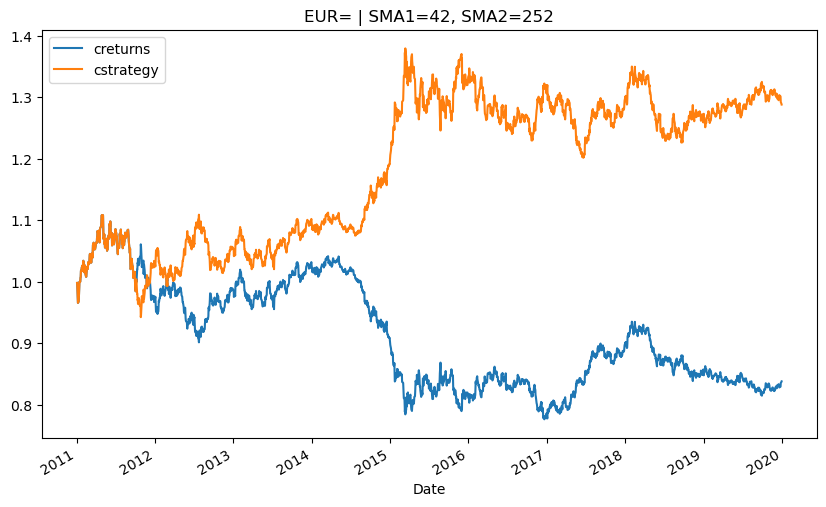

In [22]:
smabt.plot_results()

In [23]:
#in optimize_parameters the first parentheses optimize the SMA1 between 30 and 50 in steps of 2
#2nd parentheses same for the SMA2
smabt.optimize_parameters((30, 50, 2),
                          (200, 300, 2))

(array([ 48., 238.]), 1.5)

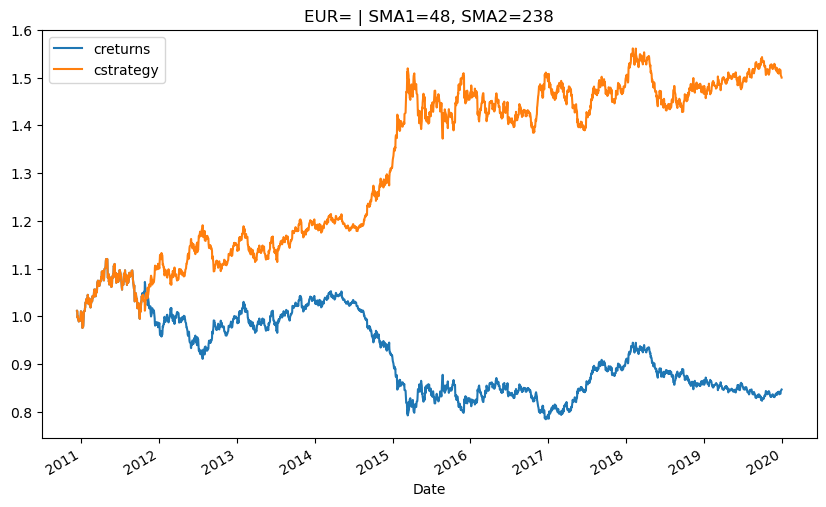

In [24]:
smabt.plot_results()

## 2. Momentum strategy

### Generalizing the Approach

In [1]:
#Same as before but this module doesn't have an optimizer
import MomVectorBacktester as Mom

In [2]:
mombt = Mom.MomVectorBacktester('XAU=', '2010-1-1',
                                '2019-12-31', 10000, 0.0)

In [3]:
mombt.run_strategy()

/Users/francescofarolfi/Desktop/UNIVERSITA'/Uni Vienna/asset management/coding/trading-strategies-backtesting/MomVectorBacktester.py:74: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data['strategy'][trades] -= self.tc


(4513.72, -9047.36)

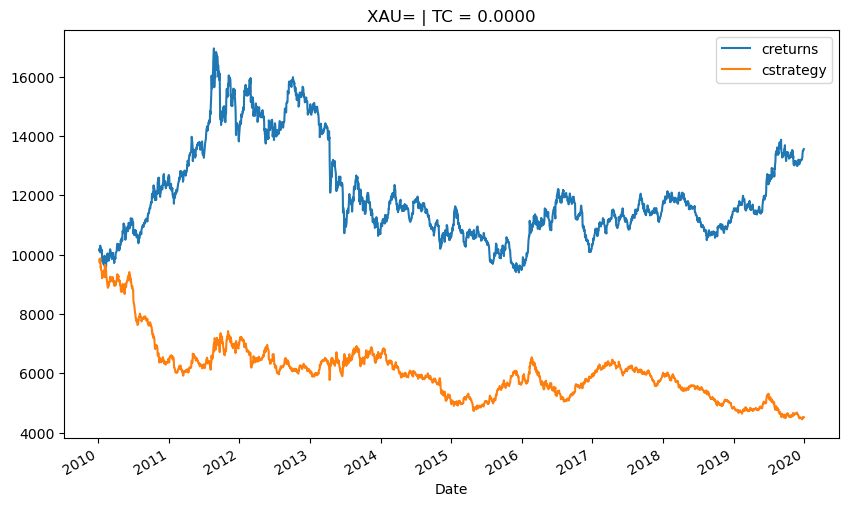

In [4]:
mombt.plot_results()

In [99]:
#the very last criteria for the function are the transaction costs in percentage, i.e. in this case 0.1%
#transaction costs are deducted from gross performance
#10000 is the start capital
mombt = Mom.MomVectorBacktester('XAU=', '2010-1-1',
                                '2019-12-31', 10000, 0.001)

In [100]:
#we see that transaction costs have a significant drag on performance
mombt.run_strategy(momentum=3)

/Users/francescofarolfi/Desktop/UNIVERSITA'/Uni Vienna/asset management/lezione 3/MomVectorBacktester.py:74: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data['strategy'][trades] -= self.tc


(10749.4, -2652.93)

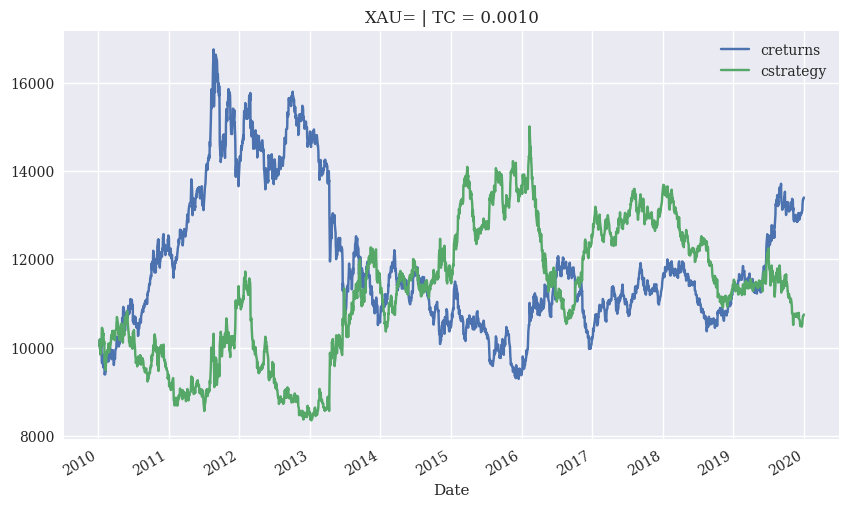

In [101]:
mombt.plot_results()

## 3. Mean-Reversion strategy

### Generalizing the Approach 

In [1]:
#very similar to MomVectorBacktester, so similar that it even inherits the classes
import MRVectorBacktester as MR

In [2]:
mrbt = MR.MRVectorBacktester('GLD', '2010-1-1', '2019-12-31',
                             10000, 0.001)

In [3]:
mrbt.run_strategy(SMA=60, threshold=9.0)

/Users/francescofarolfi/Desktop/UNIVERSITA'/Uni Vienna/asset management/lezione 3/MRVectorBacktester.py:62: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data['strategy'][trades] -= self.tc


(14781.76, 1546.61)

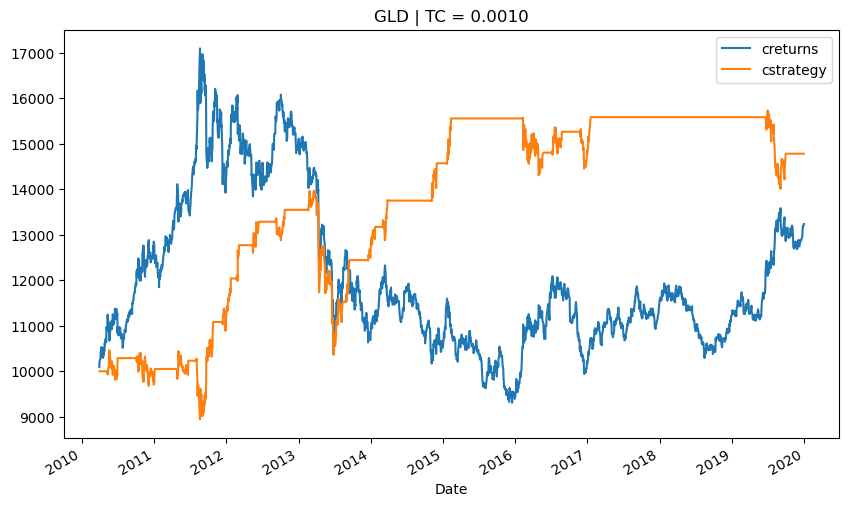

In [4]:
mrbt.plot_results()

### Brute Force Optimization

In [121]:
#since the MRVectorBacktester doesn't have a built-in optimizer the optimization is done with the following code
#SMA tests ranges from 5 to 64
#threshold is tested from 2 to 14 in 0.5 steps
#r.sort() is sorting in ascending order

r = list()
for SMA in range(5, 65):
    for threshold in np.arange(2, 15, 0.5):
        res = mrbt.run_strategy(SMA=SMA, threshold=threshold)
        r.append((res, SMA, threshold))
r.sort()

/Users/francescofarolfi/Desktop/UNIVERSITA'/Uni Vienna/asset management/lezione 3/MRVectorBacktester.py:62: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  data['strategy'][trades] -= self.tc
/Users/francescofarolfi/Desktop/UNIVERSITA'/Uni Vie

In [122]:
print(r)

[((5464.49, -7629.99), 21, 2.0), ((5493.1, -7653.17), 22, 2.0), ((5543.83, -7573.48), 12, 2.0), ((5593.12, -8000.87), 27, 2.0), ((5864.57, -7324.17), 20, 2.0), ((5923.79, -7767.88), 23, 2.0), ((5985.1, -7435.26), 18, 2.0), ((6005.81, -7550.77), 26, 2.0), ((6030.08, -7456.14), 19, 2.0), ((6062.16, -7276.77), 28, 2.0), ((6127.95, -7181.16), 13, 2.0), ((6203.87, -6876.22), 31, 2.5), ((6210.18, -7524.92), 25, 2.0), ((6215.58, -7134.57), 29, 2.0), ((6222.92, -6813.02), 30, 2.5), ((6318.67, -7275.32), 27, 3.0), ((6333.93, -6961.56), 15, 2.0), ((6417.65, -6472.48), 10, 2.0), ((6485.01, -6609.47), 21, 3.0), ((6496.75, -6853.4), 29, 2.5), ((6525.63, -6229.88), 9, 2.0), ((6541.47, -6604.8), 22, 3.0), ((6551.36, -6342.26), 42, 2.0), ((6562.28, -6923.95), 19, 2.5), ((6596.07, -6592.67), 20, 3.0), ((6596.22, -6217.63), 11, 2.0), ((6606.19, -6488.28), 21, 2.5), ((6614.15, -7036.98), 24, 2.0), ((6619.54, -6800.82), 18, 3.0), ((6657.43, -6531.31), 20, 2.5), ((6659.11, -6487.17), 22, 2.5), ((6659.72, -

In [123]:
#The code r[::-1][:5] retrieves the last 5 elements of the list r in reverse order. 
#--[::-1]: This slice notation is used to reverse the order of the elements in the list r. It creates a new list with the elements in reverse order.
#[:5]: This slice notation is used to select the first 5 elements from the reversed list. It creates a new list containing those elements.
# first number: gross performance of the strategy, i.e. not taking slippage and trading costs into account
# second number: out-/underperformance of strategy, i.e. returns of the strategy minus the benchmark
r[::-1][:5]

[((14781.76, 1546.61), 60, 9.0),
 ((14653.06, 1782.67), 64, 8.5),
 ((14592.74, 1452.51), 59, 8.5),
 ((14331.59, 1371.32), 62, 8.5),
 ((14255.29, 1368.65), 63, 8.5)]